# **Waze Project: Build churn users predictive models**

## **1. Imports and data loading**

In [73]:
# Import packages for data manipulation
import numpy as np
import pandas as pd

# Import packages for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# This lets us see all of the columns, preventing Juptyer from redacting them.
pd.set_option('display.max_columns', None)

# Import packages for data modeling
from sklearn import model_selection, metrics
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# This is the function that helps plot feature importance
from xgboost import plot_importance

# # This module lets us save our models once we fit them.
import pickle

In [74]:
# Import dataset
df0 = pd.read_csv('waze_dataset_processed.csv')

In [75]:
# Inspect the first five rows
df0.head()

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device,km_per_driving_day,percent_sessions_in_last_month
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android,138.360267,0.953670
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone,1246.901868,0.406856
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android,382.393602,0.841186
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone,304.530374,0.724968
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android,219.455667,0.499266


In [76]:
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14299 entries, 0 to 14298
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ID                              14299 non-null  int64  
 1   label                           14299 non-null  object 
 2   sessions                        14299 non-null  int64  
 3   drives                          14299 non-null  int64  
 4   total_sessions                  14299 non-null  float64
 5   n_days_after_onboarding         14299 non-null  int64  
 6   total_navigations_fav1          14299 non-null  int64  
 7   total_navigations_fav2          14299 non-null  int64  
 8   driven_km_drives                14299 non-null  float64
 9   duration_minutes_drives         14299 non-null  float64
 10  activity_days                   14299 non-null  int64  
 11  driving_days                    14299 non-null  int64  
 12  device                          

## **2. Feature engineering**

In [77]:
# Copy the df0 dataframe
df = df0.copy()

#### **`professional_driver`**

_Create a new, binary feature called `professional_driver` that is a 1 for users who had 60 or more drives <u>**and**</u> drove on 15+ days in the last month._

**Note:** The objective is to create a new feature that separates professional drivers from other drivers.

In [78]:
# Create `professional_driver` feature
df['professional_driver'] = np.where((df['drives'] >= 60) & (df['driving_days']>=15),1,0)
df.head(2)

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device,km_per_driving_day,percent_sessions_in_last_month,professional_driver
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android,138.360267,0.953670,1
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone,1246.901868,0.406856,0


#### **`total_sessions_per_day`**

_Create a new column that represents the mean number of sessions per day _since onboarding_._

In [79]:
# Create `total_sessions_per_day` feature
df['total_sessions_per_day'] = df['total_sessions'] / df['n_days_after_onboarding']

In [80]:
# Get descriptive stats
df['total_sessions_per_day'].describe()

count    14299.000000
mean         0.338207
std          1.319814
min          0.000298
25%          0.050818
50%          0.100457
75%          0.215210
max         39.763874
Name: total_sessions_per_day, dtype: float64

#### **`km_per_hour` and `km_per_drive`**

_Create a column representing the mean kilometers per hour, and kilometers per drive driven in the last month_

In [81]:
# Create `km_per_hour` feature
df['km_per_hour'] = df['driven_km_drives'] / (30*24)

In [82]:
# Create `km_per_drive` feature
df['km_per_drive'] = df['driven_km_drives'] / df['drives']
df[['km_per_hour','km_per_drive']].describe()

C:\Users\Admin\AppData\Roaming\Python\Python310\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,km_per_hour,km_per_drive
count,14299.000000,1.429900e+04
mean,5.617224,inf
std,3.479136,NaN
min,0.083946,1.008775e+00
25%,3.079611,3.325389e+01
50%,4.856313,7.490594e+01
75%,7.361072,1.854667e+02
max,29.421392,inf


In [83]:
# Convert infinite values to zero
df['km_per_drive'] = df['km_per_drive'].replace(np.inf,0)
df['km_per_drive'].describe()

count    14299.000000
mean       232.269197
std        616.197409
min          0.000000
25%         32.486524
50%         72.947059
75%        179.347527
max      15777.426560
Name: km_per_drive, dtype: float64

#### **`percent_of_sessions_to_favorite`**

_Finally, create a new column that represents the percentage of total sessions that were used to navigate to one of the users' favorite places._

This is a proxy representation for the percent of overall drives that are to a favorite place. Since total drives since onboarding are not contained in this dataset, total sessions must serve as a reasonable approximation.

People whose drives to non-favorite places make up a higher percentage of their total drives might be less likely to churn, since they're making more drives to less familiar places.

In [84]:
# Create `percent_of_sessions_to_favorite` feature
df['percent_of_sessions_to_favorite'] = (df['total_navigations_fav1'] + df['total_navigations_fav2']) / df['total_sessions']

# Get descriptive stats
df['percent_of_sessions_to_favorite'].describe()

count    14299.000000
mean         1.676347
std          9.021250
min          0.000000
25%          0.206064
50%          0.653572
75%          1.643183
max        777.563629
Name: percent_of_sessions_to_favorite, dtype: float64

## **3. Variable encoding**

#### **Dummying features**

In order to use `device` as an X variable, it needs converting to binary, since this variable is categorical.

* `Android` -> `0`
* `iPhone` -> `1`

In [85]:
# Create new `device2` variable
df['device2'] = np.where(df['device'] == 'Android',0,1)

#### **Target encoding**

The target variable is also categorical, since a user is labeled as either "churned" or "retained." Change the data type of the `label` column to be binary.

In [86]:
# Create binary `label2` column
df['label2'] = np.where(df['label'] == 'retained',0,1)

In [87]:
# Get class balance of 'label' col
df['label'].value_counts(normalize=True)

label
retained    0.822645
churned     0.177355
Name: proportion, dtype: float64

> **Approximately 18% of the users in this dataset churned. This is an unbalanced dataset, but not extremely so. It can be modeled without any class rebalancing.**

#### **Feature selection**

In [88]:
# Drop `ID` column
df = df.drop(columns='ID')

In [89]:
df.head(2)

,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device,km_per_driving_day,percent_sessions_in_last_month,professional_driver,total_sessions_per_day,km_per_hour,km_per_drive,percent_of_sessions_to_favorite,device2,label2
0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android,138.360267,0.953670,1,0.130381,3.651174,11.632058,0.700931,0,0
1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone,1246.901868,0.406856,0,0.266854,19.049890,128.186173,0.253903,1,0


## **4. Modeling workflow and model selection process**

The final modeling dataset contains 14,299 samples. This is towards the lower end of what might be considered sufficient to conduct a robust model selection process, but still doable.

1. Split the data into train/validation/test sets (60/20/20) <br>
2. Fit models and tune hyperparameters on the training set<br>
3. Perform final model selection on the validation set<br>
4. Assess the champion model's performance on the test set

To evaluate models' efficiency, we consider metrics in terms of `precision`, `recall`, `accuracy`, and `F1`. However, in order to maximize capability of accurately capturing churned users, `recall` will be the key metric to choose a champion model in this context.

### **4a. Split the data**

In [90]:
# 1. Isolate X variables
X = df.drop(columns=['label2','label','device'])

# 2. Isolate y variable
y = df['label2']

# 3. Split into train and test sets
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, 
                                                                    test_size = 0.2,
                                                                    stratify=y, 
                                                                    random_state=42)

# 4. Split into train and validate sets
X_tr, X_val, y_tr, y_val = model_selection.train_test_split(X_train, y_train, 
                                                            test_size = 0.25,
                                                            stratify=y_train, 
                                                            random_state=42)

Verify the number of samples in the partitioned data.

In [91]:
print(X_tr.shape[0])
print(X_val.shape[0])
print(X_test.shape[0])
print(y_val.value_counts())

8579
2860
2860
label2
0    2353
1     507
Name: count, dtype: int64


### **4b. Modeling**

#### **Random forest**

In [92]:
# 1. Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=42)

# 2. Create a dictionary of hyperparameters to tune
rf_cv_params = {'max_depth':[10,20, None],
               'max_features':['sqrt'],
               'min_samples_split':[2,5,10],
               'min_samples_leaf':[1,2,5],
               'n_estimators':[200,500]}

# 3. Define a list of scoring metrics to capture
scoring = ['precision', 'recall', 'accuracy', 'f1']

# 4. Instantiate the GridSearchCV object
rf_cv = model_selection.GridSearchCV(rf,
                                    rf_cv_params,
                                    scoring=scoring,
                                    cv=5,
                                    refit='recall')

In [93]:
# %%time
# rf_cv.fit(X_tr, y_tr)

In [95]:
path = r'D:\我的小楼\4. CV & Port - DA\Waze project churn prediction'

In [96]:
# build a def to save model object to pickle iterably

def write_pickle(path, model_object, save_as:str):
    '''
    In: 
        path:         path of folder where to save the pickle
        model_object: a model that needs to be pickled
        save_as:      filename for how to save the model

    Out: A call to pickle the model in the folder indicated
    '''  
    with open(path+ save_as + '.pickle','wb') as to_write:
        pickle.dump(rf_cv, to_write)

In [97]:
# save the fitted model to pickle 
# comment after saving 
# uncomment once re-running the model

# write_pickle(path, rf_cv, '\RF_cv')

In [98]:
def read_pickle(path, saved_model_name:str):
    '''
    In: 
        path:             path to folder where you want to read from
        saved_model_name: filename of pickled model you want to read in

    Out: 
        model: the pickled model 
    '''
    with open(path + saved_model_name + '.pickle', 'rb') as to_read:
        model = pickle.load(to_read)

    return model

In [101]:
# open pickle file and convert to Python object
# uncomment when re-opening the Python file

rf_cv = read_pickle(path, '\RF_cv')
rf_cv

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [10, 20, ...], 'max_features': ['sqrt'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,"['precision', 'recall', ...]"
,n_jobs,None
,refit,'recall'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [102]:
# Examine best score
rf_cv.best_score_

np.float64(0.10840163934426231)

In [103]:
# Examine best hyperparameter combo
rf_cv.best_params_

{'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 10,
 'n_estimators': 200}

In [104]:
def make_results(model_name:str, model_obj, metric: str):
    """
    Arguments:
        model_name: string, what you want the model to be called in the output
        model_obj: a fit GridSearchCV object
        metric: string, 'precision', 'recall', 'accuracy', or 'f1' - the metric that you want to refit the model.
    """
    #instantiate a dictionary of metrics
    metric_dict = {'precision': 'mean_test_precision',
                  'recall': 'mean_test_recall',
                  'accuracy':'mean_test_accuracy',
                  'f1':'mean_test_f1'}
    
    # convert cv_results_ into dataframe
    cv_results = pd.DataFrame(model_obj.cv_results_)
    
    # filter the row with the highest score in specific 'metric'
    best_result = cv_results.iloc[cv_results[metric_dict[metric]].idxmax()]
    
    # get 4 substances as 4 metrics
    precision = best_result.mean_test_precision
    recall = best_result.mean_test_recall
    accuracy = best_result.mean_test_accuracy
    f1 = best_result.mean_test_f1
    
    # create the output table
    table = pd.DataFrame({'model':[model_name],
                         'precision':[precision],
                         'recall':[recall],
                         'accuracy':[accuracy],
                         'f1':[f1]
                         }
                        )
    return table

Generate results of models into a table for easier comparison.

In [105]:
rf_results = make_results('tuned Random Forest model', rf_cv, 'recall')
rf_results

,model,precision,recall,accuracy,f1
0,tuned Random Forest model,0.497555,0.108402,0.822124,0.177624


#### **XGBoost**

In [114]:
# 1. Instantiate the XGBoost classifier
xgb = XGBClassifier(objective='binary:logistic', random_state=42)

# 2. Create a dictionary of hyperparameters to tune
xgb_cv_params ={'max_depth':[6,12],
               'min_child_weight':[3,5],
               'learning_rate':[0.1,0.2],
               'n_estimators':[100,300]}

# 3. Define a list of scoring metrics to capture
xgb_scoring = {'roc_auc':'roc_auc', 
           'precision':'precision', 
           'f1':'f1', 
           'recall':'recall', 
           'accuracy':'accuracy'}

# 3. Instantiate the GridSearchCV object
xgb_cv = model_selection.GridSearchCV(xgb,
                                     xgb_cv_params,
                                     scoring=xgb_scoring,
                                     cv=5,
                                     refit='recall', 
                                     n_jobs=-1)

In [115]:
%%time
xgb_cv.fit(X_tr, y_tr)

CPU times: total: 6.05 s
Wall time: 22.3 s


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.1, 0.2], 'max_depth': [6, 12], 'min_child_weight': [3, 5], 'n_estimators': [100, 300]}"
,scoring,"{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall', ...}"
,n_jobs,-1
,refit,'recall'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [119]:
# pickle & read the model object 

# uncomment this below line if only re-running the model 
# write_pickle(path, xgb_cv, '\XGB_cv')

In [110]:
# uncomment after opening this Jupyter notebook 
xgb_cv = read_pickle(path, '\XGB_cv')
xgb_cv

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [10, 20, ...], 'max_features': ['sqrt'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,"['precision', 'recall', ...]"
,n_jobs,None
,refit,'recall'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [117]:
# Examine best score
xgb_cv.best_score_

np.float64(0.1793809318377912)

In [118]:
# Examine best parameters
xgb_cv.best_params_

{'learning_rate': 0.2,
 'max_depth': 12,
 'min_child_weight': 5,
 'n_estimators': 300}

In [120]:
# Call 'make_results()' on the GridSearch object
xgb_results = make_results('tuned XGBoosting model', xgb_cv, 'recall')
summary_results = pd.concat([rf_results, xgb_results], axis=0, ignore_index=True)
summary_results

,model,precision,recall,accuracy,f1
0,tuned Random Forest model,0.497555,0.108402,0.822124,0.177624
1,tuned XGBoosting model,0.378042,0.179381,0.802192,0.242777


### **4b. Model selection**

Now, use the best random forest model and the best XGBoost model to predict on the validation data. Whichever performs better will be selected as the champion model.

#### **Random forest**

In [121]:
# Use random forest model to predict on validation data
rf_preds_val = rf_cv.best_estimator_.predict(X_val)

In [122]:
def get_test_scores(model_name:str, preds, y_test_data):
    '''
    Generate a table of test scores.

    In:
        model_name (string): Your choice: how the model will be named in the output table
        preds: numpy array of test predictions
        y_test_data: numpy array of y_test data

    Out:
        table: a pandas df of precision, recall, f1, and accuracy scores for your model
    '''
    accuracy = metrics.accuracy_score(y_test_data, preds)
    precision = metrics.precision_score(y_test_data, preds)
    recall = metrics.recall_score(y_test_data, preds)
    f1 = metrics.f1_score(y_test_data, preds)

    table = pd.DataFrame({'model': [model_name],
                          'precision': [precision],
                          'recall': [recall],
                          'f1': [f1],
                          'accuracy': [accuracy]
                          })

    return table

In [123]:
# Get validation scores for RF model
rf_val_result = get_test_scores('validated Random Forest', rf_preds_val, y_val)

# Append to the results table
summary_results = pd.concat([summary_results, rf_val_result], axis=0)
summary_results

,model,precision,recall,accuracy,f1
0,tuned Random Forest model,0.497555,0.108402,0.822124,0.177624
1,tuned XGBoosting model,0.378042,0.179381,0.802192,0.242777
0,validated Random Forest,0.441667,0.104536,0.817832,0.169059


#### **XGBoost**

In [124]:
# Use XGBoost model to predict on validation data
xgb_preds_val = xgb_cv.best_estimator_.predict(X_val)

# Get validation scores for XGBoost model
xgb_val_results = get_test_scores('validated XGBoosting model', xgb_preds_val, y_val)

# Append to the results table
summary_results = pd.concat([summary_results, xgb_val_results], axis=0, ignore_index=True)
summary_results

,model,precision,recall,accuracy,f1
0,tuned Random Forest model,0.497555,0.108402,0.822124,0.177624
1,tuned XGBoosting model,0.378042,0.179381,0.802192,0.242777
2,validated Random Forest,0.441667,0.104536,0.817832,0.169059
3,validated XGBoosting model,0.379592,0.183432,0.802098,0.247340


### **4c. Use champion model to predict on test data**

It is clear that **XGBoost model is the champion on the training and validation set** with significantly higher recall. Although the precision score is slightly lower than Random Forest model, yet F1 score (which indicates an aggregating effect of precision and recall) of XGBoost is still better.

In [125]:
# Use XGBoost model to predict on test data
xgb_preds_test = xgb_cv.best_estimator_.predict(X_test)

# Get test scores for XGBoost model
xgb_test_results = get_test_scores('test XGB model', xgb_preds_test, y_test)

# Append to the results table
summary_results = pd.concat([summary_results, xgb_test_results], axis=0, ignore_index=True)
summary_results

,model,precision,recall,accuracy,f1
0,tuned Random Forest model,0.497555,0.108402,0.822124,0.177624
1,tuned XGBoosting model,0.378042,0.179381,0.802192,0.242777
2,validated Random Forest,0.441667,0.104536,0.817832,0.169059
3,validated XGBoosting model,0.379592,0.183432,0.802098,0.247340
4,test XGB model,0.380597,0.201183,0.800350,0.263226


The performance of XGBoost model improves slightly on the test set, reaching recall at 20% and precision at 38%. Although we use the best parameter combo, the overall efficiency is far from acceptance.

Next step, we'll adjust the threshold to improve the model's efficiency.

## **5. Intepretation the model results**

### **5a. Confusion matrix**

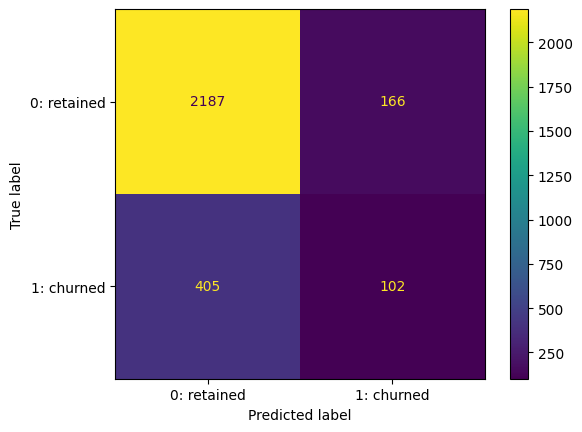

In [126]:
# Generate array of values for confusion matrix
cm = metrics.confusion_matrix(y_test,
                             xgb_preds_test,
                             labels=xgb_cv.classes_)

# Plot confusion matrix
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm,
                                     display_labels=['0: retained','1: churned'])
disp.plot();

* True Positives (users who are predicted as churned and actually churned): 102
* False Positives (users who are predicted as churned but NOT churned): 166
* True Negatives (users who are predicted as retained and actually retained): 2187
* False Negatives (employees who are predicted as retained but actually churned): 405 <br>

The model predicted three times as many false negatives than it did false positives, and it correctly identified only 20.11% of the users who actually churned (`recall`).

### **5b. Feature importance**

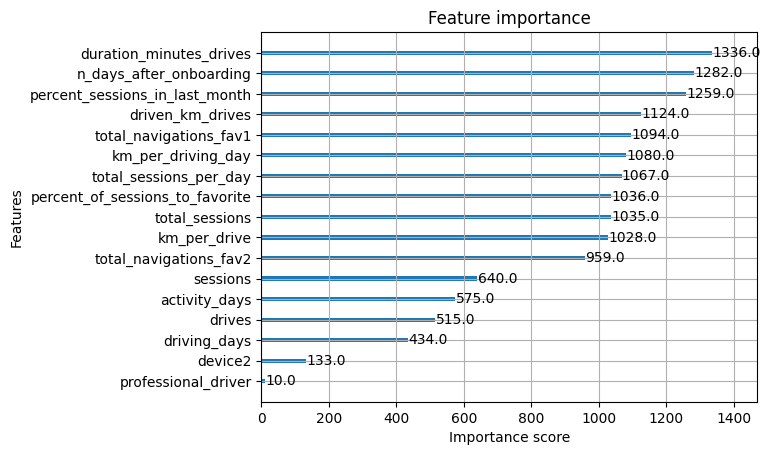

In [43]:
plot_importance(xgb_cv.best_estimator_);

### **5c. Intepretation model performance**

* Among all evaluated models, **XGBoost delivered the strongest overall performance**, achieving the highest F1-score (0.26) and recall (20.1%) on the test dataset.
* The model successfully identified meaningful churn patterns and consistently outperformed Random Forest during validation and testing.
* However, **the model still misses a substantial proportion of churners** (405 false negatives vs. 102 true positives), indicating that predicting churn remains a challenging business problem with the current data.

## **6. Conclusion & Recommendations**

> **The XGBoost model demonstrates that user churn at Waze can be predicted from engagement and driving behavior patterns.** While the current model is not yet accurate enough for fully automated retention decisions, it provides a practical foundation for identifying high-risk users, understanding churn drivers, and supporting data-driven retention strategies.

* User churn is primarily driven by behavioral and engagement signals, rather than device type or basic user attributes.
* The most influential predictors include:
    * Driving duration
    * User tenure
    * Recent engagement intensity
    * Distance driven
    * Navigation habits

This suggests that churn is linked more closely to how users interact with the platform over time than to who the users are.

* The model can serve as an early-warning system to identify users at elevated churn risk and prioritize retention interventions before disengagement occurs.
* Future improvements may require additional behavioral, product usage, and customer lifecycle data to increase recall and capture a larger share of potential churners.